# Sumativa 2 · Validación mediante remuestreo y simulación

**Universidad Andrés Bello · Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Estadística Computacional (MCDI501) · Grupo 7 · Octubre de 2026**  
Felipe Palma Barrientos · Vicente Aguila Rojas · Cristian Grandon Grandon · Jorge Gutierrez Jaramillo

**Pregunta:** ¿cuáles de los resultados de la Sumativa 1 se mantienen al repetir el análisis mediante remuestreo y cambiar algunos supuestos?

**Objetivo:** validar las tres medias, una prueba de hipótesis y tres correlaciones de S1; simular la diferencia de peso entre estados de entrega; identificar resultados confiables y resultados que requieren cautela para S3.

### Cómo utilizar este notebook

1. Guardar este archivo como **`notebooks/sumativa_2.ipynb`**, junto a `sumativa_1.ipynb`.
2. Abrir la carpeta del repositorio en VS Code o Jupyter y seleccionar el mismo entorno de S1, con NumPy, pandas, SciPy y Matplotlib. El código usa `rng=` de SciPy, disponible desde SciPy 1.15; S1 declara SciPy 1.17.
3. Ejecutar **Restart Kernel → Run All**. Las simulaciones pueden tardar varios minutos. Mantener **10.000** repeticiones para la entrega; `LOTE` controla la memoria.
4. Revisar las conclusiones y el archivo **`data/processed/resultados_validos_s2.json`**, creado por la última celda de exportación.

Todo el código nuevo está aquí: no requiere nuevos módulos ni nuevas carpetas. Los datos de S1 se leen sin modificarlos. Las figuras y tablas quedan integradas en el notebook. Reejecutar actualiza únicamente el JSON de S2.

### Índice y correspondencia con los criterios solicitados

| Sección | Contenido | Criterio / máximo |
|---|---|---:|
| 1–2 | Configuración, datos y reproducción de S1 | Trazabilidad transversal |
| 3 | Bootstrap percentil y BCa de tres medias | Bootstrap |
| 4 | Permutación del chi-cuadrado de S1 | Permutación |
| 5 | Bootstrap de tres correlaciones de S1 | Correlaciones |
| 6 | Monte Carlo y convergencia | Simulación |
| 7 | Influencia individual, extremos y supuestos | Robustez |
| 8–9 | Conclusiones, resultados para S3 y controles | Documentación |

## 1. Configuración y datos

Se utiliza la versión **MCAR de S1**: 10.999 envíos, con 1.100 faltantes artificiales en peso y 1.100 en costo. Se excluyen faltantes por variable o por pares; no se imputan ni se restauran los valores ocultados.

`0 = a tiempo`; `1 = fuera de plazo`. El peso se expresa en gramos; el costo, en USD según S1. La unidad del descuento no está documentada: **no se interpreta como porcentaje**.

Cada análisis usa una semilla distinta y fija. Así, ejecutar de nuevo una sección conserva sus resultados. Las cifras de S1 se verifican antes de simular.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import subprocess
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

B = 10_000                 # Remuestras y permutaciones, por análisis.
M = 10_000                 # Iteraciones Monte Carlo, por escenario.
LOTE = 50                  # Menor lote = menor uso de memoria.
ALFA = 0.05
SEMILLAS = {
    "medias": [101, 102, 103], "permutacion": 201,
    "correlaciones": [301, 302, 303], "lognormal": 401,
    "gamma": 402, "diferencia_bootstrap": 403,
    "descuento_filtrado": 501, "correlacion_filtrada": 502,
    "escenario_inferior": 601, "escenario_superior": 602,
}
COMMIT_S1 = "0c7ffaca4e45525ab434f6c9305128221e4ef1c4"
REPO_URL = "https://github.com/jorge170102/ESTAD-STICA-COMPUTACIONAL---Grupo-7--MCDI501.202682.1914.EL.ON"
HASH_DATOS_S1 = "1a7f8a5c4da839e481ff2dc93e30c7f64205407a2bd62ae94be4265027ca0714"

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/processed/ecommerce_mcar.csv").is_file()
             and (p / "notebooks/sumativa_1.ipynb").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook dentro del repositorio, con los archivos de S1.")

# Incorporar la raíz del proyecto a las rutas de importación
import sys

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

RUTA_DATOS = RAIZ / "data/processed/ecommerce_mcar.csv"
RUTA_SALIDA = RAIZ / "data/processed/resultados_validos_s2.json"

# Normalizar solo saltos de línea permite verificar el CSV también en Windows.
hash_datos = hashlib.sha256(RUTA_DATOS.read_bytes().replace(b"\r\n", b"\n")).hexdigest()
assert hash_datos == HASH_DATOS_S1, "El CSV cambió: revisar la línea base de S1 antes de continuar."
df = pd.read_csv(RUTA_DATOS)
OBJETIVO = "Reached.on.Time_Y.N"
VARIABLES = ["Weight_in_gms", "Cost_of_the_Product", "Discount_offered"]
NOMBRES = dict(zip(VARIABLES, ["Peso (g)", "Costo (USD)", "Descuento (unidad no indicada)"]))

assert df.shape == (10_999, 12)
assert df.ID.notna().all() and df.ID.is_unique
assert df[OBJETIVO].isin([0, 1]).all()
assert df["Mode_of_Shipment"].isin(["Flight", "Road", "Ship"]).all()
assert df["Weight_in_gms"].isna().sum() == 1_100
assert df["Cost_of_the_Product"].isna().sum() == 1_100
assert df["Discount_offered"].notna().all()
for variable in VARIABLES:
    assert np.isfinite(df[variable].dropna()).all()

VERSIONES = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "Matplotlib": matplotlib.__version__}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)
AZUL, NARANJA, VERDE = "#23648A", "#CF7B28", "#2F826B"
display(pd.Series(VERSIONES, name="Versión ejecutada").to_frame())
print(f"Datos verificados: {len(df):,} envíos. Referencia S1: {COMMIT_S1[:7]}.")

,Versión ejecutada
Python,3.14.7
NumPy,2.5.3
pandas,3.0.6
SciPy,1.18.1
Matplotlib,3.11.2


Datos verificados: 10,999 envíos. Referencia S1: 0c7ffac.


## 2. Reproducir los resultados propios de S1

Se reconstruyen las medias y sus IC t de Student con los mismos datos y fórmulas de `src/inferencia.py`. Se comprueban contra las salidas publicadas en S1; la tolerancia de 0,001 corresponde a su redondeo a tres decimales.

También se recuperan el chi-cuadrado, la comparación de Welch y las tres correlaciones de la matriz de S1. **La simulación utilizará las medias, desviaciones y tamaños por grupo de S1 con precisión completa**, antes del redondeo de las tablas.

In [2]:
def resumen_media(x):
    """Media e IC t bilateral del 95 %, usando observaciones disponibles."""
    x = np.asarray(x, dtype=float)
    n, media, de = len(x), x.mean(), x.std(ddof=1)
    ee = de / np.sqrt(n)
    margen = stats.t.ppf(1 - ALFA / 2, n - 1) * ee
    return {"n": n, "media": media, "de": de, "ee": ee,
            "ic_t_inf": media - margen, "ic_t_sup": media + margen}

base_medias = pd.DataFrame({v: resumen_media(df[v].dropna()) for v in VARIABLES}).T
base_medias.index.name = "variable"
referencias_medias = np.array([
    [3633.880, 3601.646, 3666.115],
    [210.239, 209.293, 211.186],
    [13.373, 13.070, 13.676],
])
np.testing.assert_allclose(base_medias[["media", "ic_t_inf", "ic_t_sup"]],
                           referencias_medias, atol=0.001, rtol=0)
display(base_medias.rename(index=NOMBRES).round(4))

peso_tiempo = df.loc[df[OBJETIVO].eq(0), "Weight_in_gms"].dropna().to_numpy()
peso_fuera = df.loc[df[OBJETIVO].eq(1), "Weight_in_gms"].dropna().to_numpy()
grupos_s1 = pd.DataFrame([resumen_media(peso_tiempo), resumen_media(peso_fuera)],
                         index=["A tiempo", "Fuera de plazo"])
# S1, sección 5.3, publica este resumen por grupo con dos decimales.
np.testing.assert_allclose(grupos_s1[["n", "media", "de"]],
    [[3992, 4166.35, 1574.66], [5907, 3274.03, 1577.85]], atol=0.006, rtol=0)
display(grupos_s1[["n", "media", "de"]].round(4))

delta_s1 = peso_fuera.mean() - peso_tiempo.mean()
v_t = peso_tiempo.var(ddof=1) / len(peso_tiempo)
v_f = peso_fuera.var(ddof=1) / len(peso_fuera)
ee_delta = np.sqrt(v_t + v_f)
gl_welch = (v_t + v_f)**2 / (v_t**2 / (len(peso_tiempo)-1) + v_f**2 / (len(peso_fuera)-1))
ic_delta_s1 = delta_s1 + np.array([-1, 1]) * stats.t.ppf(0.975, gl_welch) * ee_delta
welch = stats.ttest_ind(peso_fuera, peso_tiempo, equal_var=False)
np.testing.assert_allclose([delta_s1, *ic_delta_s1], [-892.316, -955.611, -829.021], atol=0.001, rtol=0)

tabla_contingencia = pd.crosstab(df.Mode_of_Shipment, df[OBJETIVO])
chi_s1, p_chi_s1, gl_chi, esperados = stats.chi2_contingency(tabla_contingencia, correction=False)
np.testing.assert_allclose([chi_s1, p_chi_s1], [0.743, 0.690], atol=0.001, rtol=0)
v_cramer = np.sqrt(chi_s1 / len(df))

PARES = [("Weight_in_gms", "Discount_offered", "Peso y descuento"),
         ("Customer_care_calls", "Cost_of_the_Product", "Llamadas y costo"),
         ("Customer_rating", "Weight_in_gms", "Valoración y peso")]
referencias_rho = [-0.318, 0.293, -0.010]  # Matriz publicada de S1.
base_correlaciones = []
for (a, b, nombre), referencia in zip(PARES, referencias_rho):
    pares = df[[a, b]].dropna()
    rho = stats.spearmanr(pares[a], pares[b]).statistic
    assert abs(rho - referencia) < 0.001
    base_correlaciones.append({"relacion": nombre, "n": len(pares), "rho_s1": rho})
base_correlaciones = pd.DataFrame(base_correlaciones)
display(base_correlaciones.round(4))
print(f"Chi-cuadrado S1 = {chi_s1:.6f}; p = {p_chi_s1:.6f}; V de Cramér = {v_cramer:.4f}.")
print(f"Welch S1: diferencia = {delta_s1:.3f} g; IC95% = {ic_delta_s1.round(3)}; p = {welch.pvalue:.3g}.")
print("Línea base de S1 reproducida: todas las comprobaciones coinciden dentro del redondeo.")

,n,media,de,ee,ic_t_inf,ic_t_sup
variable,,,,,,
Peso (g),9899.0,3633.8803,1636.1330,16.4446,3601.6456,3666.1150
Costo (USD),9899.0,210.2391,48.0459,0.4829,209.2925,211.1857
Descuento (unidad no indicada),10999.0,13.3732,16.2055,0.1545,13.0703,13.6761


,n,media,de
A tiempo,3992,4166.3492,1574.6604
Fuera de plazo,5907,3274.0334,1577.8499


,relacion,n,rho_s1
0,Peso y descuento,9899,-0.3177
1,Llamadas y costo,9899,0.2932
2,Valoración y peso,9899,-0.0104


Chi-cuadrado S1 = 0.743436; p = 0.689549; V de Cramér = 0.0082.
Welch S1: diferencia = -892.316 g; IC95% = [-955.611 -829.021]; p = 4.14e-161.
Línea base de S1 reproducida: todas las comprobaciones coinciden dentro del redondeo.


## 3. Bootstrap: ¿son confiables los intervalos de las tres medias?

**Método.** Para cada variable se toman 10.000 muestras con reemplazo, cada una del mismo tamaño que sus observaciones disponibles. Se calcula una media por muestra.

- **Percentil:** usa los percentiles 2,5 y 97,5 de las medias remuestreadas.
- **BCa:** ajusta por sesgo y aceleración; SciPy calcula la corrección usando jackknife.
- **Clásico de S1:** intervalo t de Student. Se contrastan límites, anchura y error estándar.

Los dos IC bootstrap usan **las mismas 10.000 remuestras**, evitando confundir diferencias de método con nuevas simulaciones. La distribución graficada es la de las **medias**, no la de los envíos individuales.

**Supuestos.** Los tres métodos requieren observaciones suficientemente independientes y una muestra adecuada para la población de interés. Bootstrap no exige normalidad de los datos, pero tampoco corrige sesgos de selección. La aproximación t mejora con muestras grandes y varianza finita; BCa puede ajustar asimetría, aunque no siempre es superior. El análisis se condiciona a los valores disponibles bajo el mecanismo MCAR de S1.

In [3]:
def bootstrap_media(x, semilla):
    """IC BCa de SciPy e IC percentil a partir de las mismas remuestras."""
    x = np.asarray(x, dtype=float)
    resultado = stats.bootstrap((x,), np.mean, vectorized=True,
        n_resamples=B, batch=LOTE, confidence_level=0.95, method="BCa",
        rng=np.random.default_rng(semilla))
    distribucion = resultado.bootstrap_distribution
    percentil = np.quantile(distribucion, [0.025, 0.975])
    bca = np.array(resultado.confidence_interval)
    assert len(distribucion) == B and np.isfinite(bca).all()
    return distribucion, percentil, bca

distribuciones_medias, filas = {}, []
for variable, semilla in zip(VARIABLES, SEMILLAS["medias"]):
    x = df[variable].dropna().to_numpy()
    distribucion, percentil, bca = bootstrap_media(x, semilla)
    distribuciones_medias[variable] = distribucion
    base = base_medias.loc[variable]
    ancho_t = base.ic_t_sup - base.ic_t_inf
    filas.append({"variable": variable, **base.to_dict(),
        "percentil_inf": percentil[0], "percentil_sup": percentil[1],
        "bca_inf": bca[0], "bca_sup": bca[1],
        "ancho_t": ancho_t, "ancho_percentil": np.diff(percentil)[0],
        "ancho_bca": np.diff(bca)[0],
        "cambio_ancho_bca_pct": 100 * (np.diff(bca)[0] / ancho_t - 1),
        "desplazamiento_limites_en_ee": np.max(np.abs(bca - [base.ic_t_inf, base.ic_t_sup])) / base.ee,
        "sesgo_bootstrap": distribucion.mean() - x.mean(),
        "ee_bootstrap": distribucion.std(ddof=1),
        "asimetria_datos": stats.skew(x, bias=False),
        "asimetria_medias_bootstrap": stats.skew(distribucion, bias=False)})
bootstrap_medias = pd.DataFrame(filas).set_index("variable")

tabla_ic = pd.DataFrame(index=VARIABLES)
tabla_ic["n"] = base_medias.n.astype(int)
tabla_ic["Media"] = base_medias.media.round(3)
for titulo, inferior, superior in [("IC clásico S1", "ic_t_inf", "ic_t_sup"),
        ("IC percentil", "percentil_inf", "percentil_sup"), ("IC BCa", "bca_inf", "bca_sup")]:
    tabla_ic[titulo] = bootstrap_medias.apply(lambda r: f"[{r[inferior]:.3f}; {r[superior]:.3f}]", axis=1)
display(tabla_ic.rename(index=NOMBRES))
display(bootstrap_medias[["ancho_t", "ancho_percentil", "ancho_bca", "sesgo_bootstrap",
                         "cambio_ancho_bca_pct", "desplazamiento_limites_en_ee"]].rename(index=NOMBRES).round(4))

,n,Media,IC clásico S1,IC percentil,IC BCa
Peso (g),9899,3633.880,[3601.646; 3666.115],[3602.474; 3666.183],[3602.091; 3665.766]
Costo (USD),9899,210.239,[209.293; 211.186],[209.302; 211.173],[209.312; 211.182]
Descuento (unidad no indicada),10999,13.373,[13.070; 13.676],[13.067; 13.678],[13.072; 13.684]


,ancho_t,ancho_percentil,ancho_bca,sesgo_bootstrap,cambio_ancho_bca_pct,desplazamiento_limites_en_ee
variable,,,,,,
Peso (g),64.4695,63.7093,63.6754,0.2551,-1.2316,0.0271
Costo (USD),1.8932,1.8716,1.8706,-0.0015,-1.1933,0.0398
Descuento (unidad no indicada),0.6058,0.6113,0.6115,-0.0014,0.9405,0.0485


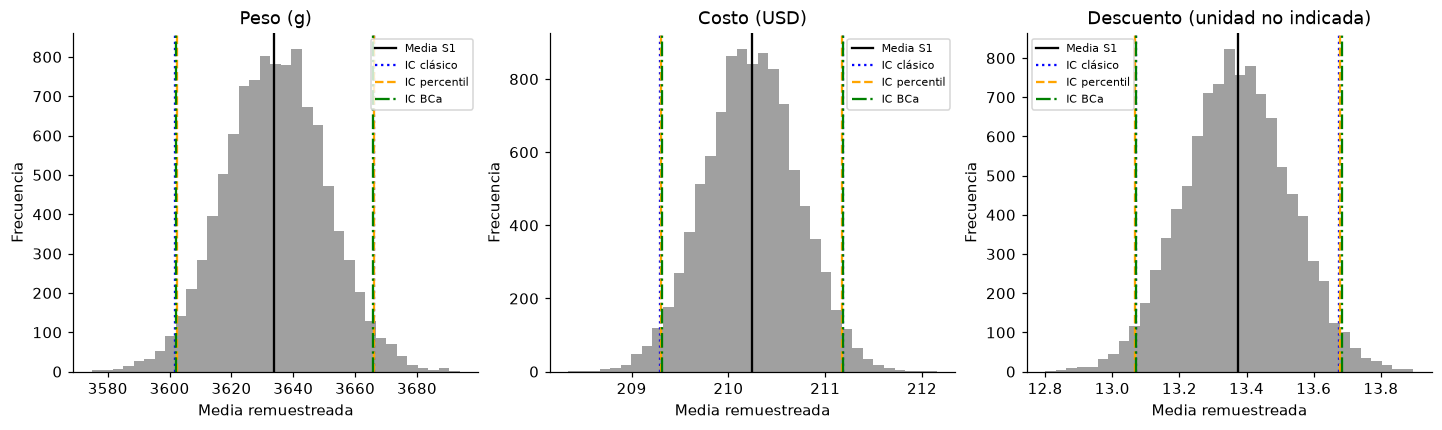

**Peso (g).** La media es **3633.880**. El ancho BCa cambia **-1.23%** frente al clásico; el mayor desplazamiento de sus límites equivale a **0.027** errores estándar. El sesgo bootstrap estimado es **0.2551**. Asimetría de los datos: -0.25; de las medias remuestreadas: 0.00.

**Costo (USD).** La media es **210.239**. El ancho BCa cambia **-1.19%** frente al clásico; el mayor desplazamiento de sus límites equivale a **0.040** errores estándar. El sesgo bootstrap estimado es **-0.0015**. Asimetría de los datos: -0.15; de las medias remuestreadas: -0.01.

**Descuento (unidad no indicada).** La media es **13.373**. El ancho BCa cambia **+0.94%** frente al clásico; el mayor desplazamiento de sus límites equivale a **0.048** errores estándar. El sesgo bootstrap estimado es **-0.0014**. Asimetría de los datos: 1.80; de las medias remuestreadas: 0.01.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, variable in zip(axes, VARIABLES):
    r = bootstrap_medias.loc[variable]
    ax.hist(distribuciones_medias[variable], bins=35, color="gray", alpha=0.75)
    ax.axvline(r.media, color="black", label="Media S1")
    for campo, color, estilo, etiqueta in [("ic_t", "blue", ":", "IC clásico"),
            ("percentil", "orange", "--", "IC percentil"), ("bca", "green", "-.", "IC BCa")]:
        ax.axvline(r[campo + "_inf"], color=color, ls=estilo, label=etiqueta)
        ax.axvline(r[campo + "_sup"], color=color, ls=estilo)
    ax.set(title=NOMBRES[variable], xlabel="Media remuestreada", ylabel="Frecuencia")
    ax.legend(fontsize=7)
plt.show()
plt.close(fig)

for variable, r in bootstrap_medias.iterrows():
    display(Markdown(f"**{NOMBRES[variable]}.** La media es **{r.media:.3f}**. "
        f"El ancho BCa cambia **{r.cambio_ancho_bca_pct:+.2f}%** frente al clásico; "
        f"el mayor desplazamiento de sus límites equivale a **{r.desplazamiento_limites_en_ee:.3f}** errores estándar. "
        f"El sesgo bootstrap estimado es **{r.sesgo_bootstrap:.4f}**. "
        f"Asimetría de los datos: {r.asimetria_datos:.2f}; de las medias remuestreadas: {r.asimetria_medias_bootstrap:.2f}."))

**Lectura sencilla.** La proximidad de los intervalos respalda la precisión calculada en S1 bajo los mismos supuestos. Aunque los descuentos individuales son asimétricos, promediar muchos envíos hace más simétrica la distribución de su media. Por eso puede existir acuerdo entre t, percentil y BCa.

Este acuerdo no demuestra que el promedio del descuento sea resistente a retirar valores altos: eso se evalúa en la sección 7. Un IC del 95 % expresa la cobertura de un procedimiento en muestreos repetidos; no contiene necesariamente al 95 % de los productos ni garantiza representatividad.

## 4. Prueba de permutación: 

### 4.1. Asociación entre modo de transporte y cumplimiento del plazo de entrega

Se realiza una prueba de permutación para evaluar la asociación entre el modo de transporte y el cumplimiento del plazo de entrega, utilizando como estadístico de contraste el chi-cuadrado de Pearson. Este procedimiento permite complementar y verificar los resultados obtenidos en la fase S1 mediante una aproximación empírica a la distribución del estadístico bajo la hipótesis nula.

Hipótesis del contraste:

**H₀:** El modo de transporte y el cumplimiento del plazo de entrega son estadísticamente independientes.

**H₁:** Existe una asociación estadística entre el modo de transporte y el cumplimiento del plazo de entrega.

Procedimiento:

Se calcula inicialmente el estadístico chi-cuadrado de Pearson utilizando la tabla de contingencia observada. Posteriormente, se realizan 10.000 permutaciones aleatorias de las etiquetas correspondientes al cumplimiento del plazo de entrega, manteniendo fijos los modos de transporte y conservando las frecuencias marginales de ambas variables.

En cada permutación se reconstruye la tabla de contingencia y se calcula nuevamente el estadístico chi-cuadrado. De esta manera, se obtiene una distribución nula empírica que representa los valores del estadístico esperables bajo la hipótesis de independencia, suponiendo que las observaciones son independientes y que las etiquetas de cumplimiento son intercambiables bajo dicha hipótesis.

El valor p de permutación se estima mediante:

$$p_{\text{perm}}=
\frac{1+\sum_{b=1}^{B}I(\chi_b^2\geq\chi_{\text{obs}}^2)}{B+1}
$$

Donde:

$B=10.000$ corresponde al número de permutaciones realizadas.

$\chi_{\text{obs}}^2$ es el estadístico calculado con los datos originales.

$\chi_b^2$ es el estadístico obtenido en la permutación (b).

$I(\cdot)$ es una función indicadora que toma el valor 1 cuando se cumple la condición y 0 en caso contrario.

La incorporación de una unidad en el numerador y el denominador evita obtener un valor p estimado igual a cero cuando ninguna de las permutaciones genera un estadístico tan extremo como el observado.

Adicionalmente, se estima el error estándar de Monte Carlo del valor p mediante:

$$
EE_{\text{MC}}\approx
\sqrt{\frac{\hat p(1-\hat p)}{B}}
$$

Este indicador cuantifica la variabilidad numérica asociada al uso de un número finito de permutaciones. No representa la incertidumbre sobre la probabilidad de que la hipótesis nula sea verdadera.

Finalmente, el valor p obtenido mediante permutación se compara con el de la prueba chi-cuadrado de Pearson de S1, con el propósito de evaluar la consistencia de las conclusiones estadísticas obtenidas mediante ambos procedimientos.

,Resultado
chi2_observado,0.7434
gl,2
p_s1,0.6895
p_permutacion,0.6892
ee_monte_carlo_p,0.0046
diferencia_p,-0.0003
permutaciones,10000
esperado_minimo,709.8245
v_cramer,0.0082
rechaza_s1,False


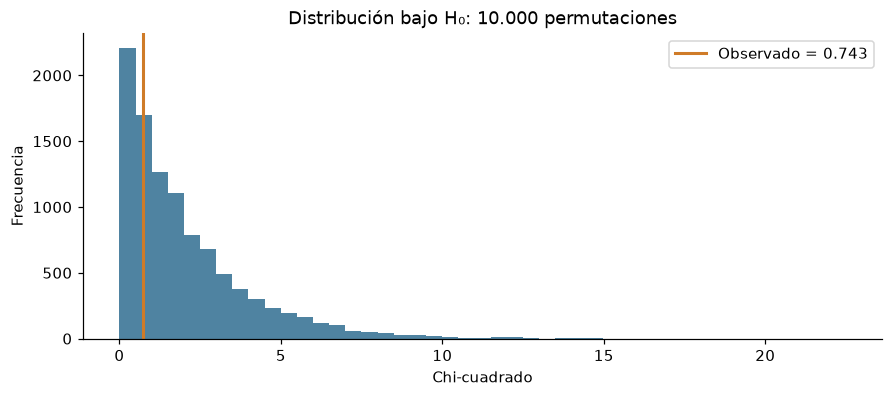

**Resultado.** S1 obtuvo p = **0.6895** y la permutación obtiene p = **0.6892**. Su diferencia es 0.0003; el margen Monte Carlo aproximado del p es ±0.0091. Ambos métodos coinciden en la decisión con α = 0,05. El menor conteo esperado es 709.8.

In [5]:
rng_perm = np.random.default_rng(SEMILLAS["permutacion"])
codigos = pd.Categorical(df.Mode_of_Shipment, categories=tabla_contingencia.index).codes
etiquetas = df[OBJETIVO].to_numpy(dtype=int)
chi_nulos = np.empty(B)
for i in range(B):
    mezcladas = rng_perm.permutation(etiquetas)
    tabla = np.bincount(2 * codigos + mezcladas, minlength=6).reshape(3, 2)
    chi_nulos[i] = np.sum((tabla - esperados)**2 / esperados)

extremos = int(np.count_nonzero(chi_nulos >= chi_s1 - 1e-12))
p_perm = (extremos + 1) / (B + 1)
ee_p_perm = np.sqrt(p_perm * (1 - p_perm) / B)
permutacion = {"chi2_observado": chi_s1, "gl": int(gl_chi),
    "p_s1": p_chi_s1, "p_permutacion": p_perm, "ee_monte_carlo_p": ee_p_perm,
    "diferencia_p": p_perm - p_chi_s1, "permutaciones": B,
    "esperado_minimo": float(esperados.min()), "v_cramer": v_cramer,
    "rechaza_s1": bool(p_chi_s1 < ALFA), "rechaza_permutacion": bool(p_perm < ALFA)}
display(pd.DataFrame([permutacion]).T.rename(columns={0: "Resultado"}))

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.hist(chi_nulos, bins=45, color=AZUL, alpha=0.8)
ax.axvline(chi_s1, color=NARANJA, lw=2, label=f"Observado = {chi_s1:.3f}")
ax.set(title="Distribución bajo H₀: 10.000 permutaciones", xlabel="Chi-cuadrado", ylabel="Frecuencia")
ax.legend()
plt.show()
plt.close(fig)

display(Markdown(f"**Resultado.** S1 obtuvo p = **{p_chi_s1:.4f}** y la permutación obtiene "
    f"p = **{p_perm:.4f}**. Su diferencia es {abs(p_perm-p_chi_s1):.4f}; "
    f"el margen Monte Carlo aproximado del p es ±{1.96*ee_p_perm:.4f}. "
    f"Ambos métodos {'coinciden' if (p_perm < ALFA) == (p_chi_s1 < ALFA) else 'difieren'} "
    f"en la decisión con α = 0,05. El menor conteo esperado es {esperados.min():.1f}."))

**Conclusión sencilla.** No se detecta asociación estadísticamente significativa entre transporte y puntualidad en estos datos. Esto **no demuestra que los transportes sean equivalentes o independientes**; significa que la evidencia disponible no permite rechazar H₀.

Los conteos esperados son altos, por lo que la aproximación chi-cuadrado de S1 es adecuada y eficiente. La permutación ofrece una comprobación con los márgenes observados; aquí no hay un motivo fuerte para preferirla como sustituto. Ambas dependen de la independencia entre envíos, que no puede verificarse con los campos disponibles. El V de Cramér pequeño complementa el p: la asociación observada también es pequeña. No se justifica recomendar un cambio de transporte solo con este contraste.


### 4.2. Diferencia de peso promedio según cumplimiento del plazo de entrega

Se realiza una prueba de permutación para evaluar si existen diferencias estadísticamente significativas en el peso promedio de los productos entre los envíos realizados a tiempo y aquellos registrados fuera de plazo. Este procedimiento complementa el análisis desarrollado en la fase S1 y permite contrastar la diferencia observada mediante una distribución nula generada empíricamente.

Hipótesis del contraste:

**H₀:** El peso promedio poblacional de los productos es igual entre los envíos realizados a tiempo y aquellos registrados fuera de plazo.

**H₁:** El peso promedio poblacional de los productos difiere entre ambos grupos.

En términos matemáticos:

$$
H_0:\mu_{\text{fuera}}-\mu_{\text{tiempo}}=0
$$

$$
H_1:\mu_{\text{fuera}}-\mu_{\text{tiempo}}\neq0
$$

Procedimiento:

Inicialmente, se calcula la diferencia observada entre las medias muestrales de ambos grupos, utilizando como estadístico de contraste:

$$
\Delta_{\text{obs}}=\bar X_{\text{fuera}}-\bar X_{\text{tiempo}}
$$

Posteriormente, se realizan $(B)$ permutaciones aleatorias de las observaciones, reasignando los pesos entre ambos grupos sin reemplazo y conservando sus tamaños muestrales originales. En cada permutación se calcula nuevamente la diferencia de medias.

Este procedimiento genera una distribución nula empírica que representa las diferencias de medias esperables cuando las etiquetas de cumplimiento son intercambiables respecto del peso de los productos, suponiendo independencia entre las observaciones.

Bajo esta hipótesis, la distribución de las diferencias obtenidas mediante permutación se encuentra centrada alrededor de cero.

El valor p bilateral de permutación se estima mediante:

$$
p_{\text{perm}}=
\frac{1+\sum_{b=1}^{B}I\left(|\Delta_b^*|\geq|\Delta_{\text{obs}}|\right)}{B+1}
$$

Donde:

$B$ corresponde al número de permutaciones realizadas.

$\Delta_{\text{obs}}$ representa la diferencia de medias observada en los datos originales.

$\Delta_b^*$ corresponde a la diferencia de medias obtenida en la permutación (b).

$I(\cdot)$ es una función indicadora que toma el valor 1 cuando la diferencia permutada es igual o más extrema que la observada, en valor absoluto.

La utilización de valores absolutos permite desarrollar un contraste bilateral, considerando diferencias en ambas direcciones. Asimismo, la incorporación de una unidad en el numerador y el denominador evita obtener un valor p estimado igual a cero cuando ninguna permutación genera una diferencia tan extrema como la observada.

Contraste complementario mediante la prueba t de Welch:

Adicionalmente, se aplica una prueba t de Welch para comparar las medias de ambos grupos sin asumir igualdad de varianzas poblacionales.

El estadístico se calcula mediante:

$$
t=
\frac{\bar X_{\text{fuera}}-\bar X_{\text{tiempo}}}
{\sqrt{\frac{s_{\text{fuera}}^2}{n_{\text{fuera}}}+
\frac{s_{\text{tiempo}}^2}{n_{\text{tiempo}}}}}
$$

Donde $s^2$ representa la varianza muestral y $n$ el tamaño de cada grupo.

Finalmente, se comparan los valores p obtenidos mediante la prueba de permutación y la prueba t de Welch, con el propósito de evaluar la consistencia de las conclusiones estadísticas sobre las diferencias en el peso promedio de los productos según el cumplimiento del plazo de entrega.


El peso promedio de los productos enviados a tiempo es 892.316 gramos mayor que el de los productos que no se enviaron a tiempo.


,"Resultado ,Weight_in_gms"
n,9899
Diferencia observada,-892.3158
IC para Distribución nula,"[-133.752, 132.388]"
p_value permutacion,0.0001
p_value t-Welch,0.0
Diferencia_p,0.0001
Permutaciones,10000
rechaza_s1,True
rechaza_permutacion,True


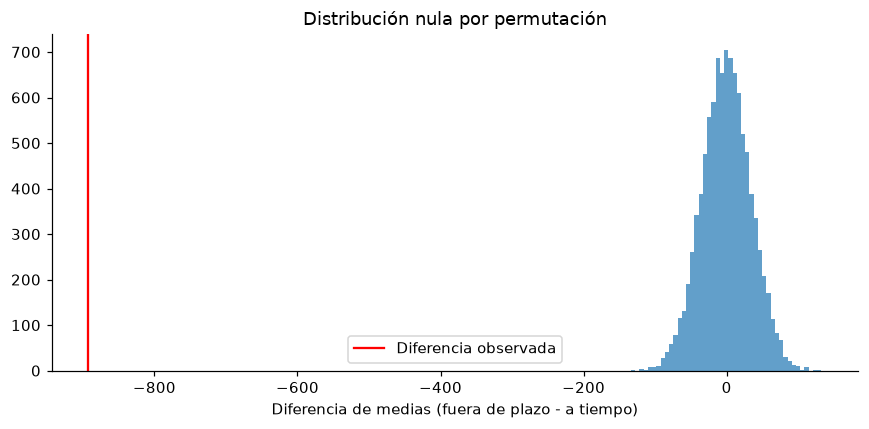

In [6]:
SEED = 42
B = 10_000
ALFA = 0.05

def prueba_permutacion(df,variable='Weight_in_gms'):
    sub=df[[variable,'Reached.on.Time_Y.N']].dropna();
    x=sub[variable].to_numpy(dtype=float);
    g=sub['Reached.on.Time_Y.N'].to_numpy()
    a=x[g==0]
    b=x[g==1]
    obs=b.mean()-a.mean()
    rng=np.random.default_rng(SEED)
    n1=len(b)
    n=len(x)
    suma_total=x.sum()
    reps=np.empty(B)
    for i in range(B):
        ix=rng.choice(n, size=n1, replace=False)
        s1=x[ix].sum()
        reps[i]=s1/n1-(suma_total-s1)/(n-n1)
    p=(1+np.count_nonzero(np.abs(reps)>=abs(obs)))/(B+1)
    welch=stats.ttest_ind(b,a,equal_var=False)
    perm = {"n":n,"Diferencia observada":obs, "IC para Distribución nula": f"[{reps.min():.3f}, {reps.max():.3f}]", 
            "p_value permutacion":p,"p_value t-Welch":welch.pvalue, "Diferencia_p": p - welch.pvalue, 
            "Permutaciones": B, "rechaza_s1": bool(p < ALFA), "rechaza_permutacion": bool(welch.pvalue < ALFA)}
    if obs < 0:
        print(f"El peso promedio de los productos enviados a tiempo es "
          f"{abs(obs):.3f} gramos mayor que el de los productos que no se enviaron a tiempo.")
    elif obs > 0:
        print(f"El peso promedio de los productos que no se enviaron a tiempo "
          f"es {abs(obs):.3f} gramos mayor que el de los productos enviados a tiempo.")
    else:
        print("No existen diferencias en el peso promedio entre ambos grupos.")
    display(pd.DataFrame([perm]).T.rename(columns={0: f"Resultado ,{variable}"}))
    return {'variable':variable,'n':n,'diferencia':obs,'p_permutacion':p,'p_welch':welch.pvalue,'replicas':reps}

resultado_prueba = prueba_permutacion(df)

def figura_permutacion(r):
    plt.figure(figsize=(8,4))
    plt.hist(r['replicas'],bins=45,alpha=.7)
    plt.axvline(r['diferencia'],color='red',label='Diferencia observada')
    plt.title('Distribución nula por permutación')
    plt.xlabel('Diferencia de medias (fuera de plazo - a tiempo)')
    plt.legend()
    plt.tight_layout();plt.show()

figura_permutacion(resultado_prueba)

**Interpretación de resultados:**

Un valor p inferior al nivel de significancia establecido $\alpha=0.05$ proporciona evidencia estadística para rechazar la hipótesis nula. En tal caso, se concluye que existen diferencias estadísticamente significativas en el peso promedio entre ambos grupos.

La distribución nula obtenida mediante permutaciones permite visualizar qué diferencias serían esperables bajo la hipótesis de intercambiabilidad y comparar estas con la diferencia efectivamente observada en los datos.

## 5. ¿Qué tan estables son las correlaciones de S1?

Se seleccionan tres relaciones de la matriz de Spearman de S1 para estudiar distintos patrones:

| Relación | Motivo de selección |
|---|---|
| Peso y descuento | Asociación negativa; permite estudiar sensibilidad a descuentos altos. |
| Llamadas y costo | Asociación positiva entre características del envío y atención al cliente. |
| Valoración y peso | Asociación cercana a cero; permite examinar si un efecto pequeño es preciso. |

Se remuestrean **pares completos** 10.000 veces por relación y se calculan IC percentiles del 95 %. Se vuelven a calcular los rangos de Spearman **dentro de cada remuestra**, incluyendo el tratamiento de empates; no se remuestrean rangos fijados de antemano.

Un IC que excluye cero respalda la estabilidad del signo. Un IC estrecho que incluye cero puede reflejar una asociación pequeña bien delimitada: **no significa necesariamente alta variabilidad**. Se reportan anchura y error estándar sin imponer un umbral universal de estabilidad. Los IC son individuales, exploratorios y sin ajuste conjunto por multiplicidad.

,n,rho_s1,IC bootstrap 95 %,ee_bootstrap,ancho_ic,incluye_cero,signo
relacion,,,,,,,
Peso y descuento,9899,-0.3177,[-0.3357; -0.2994],0.0093,0.0363,False,Negativo estable
Llamadas y costo,9899,0.2932,[0.2731; 0.3126],0.0101,0.0394,False,Positivo estable
Valoración y peso,9899,-0.0104,[-0.0299; 0.0092],0.0100,0.0391,True,Signo no resuelto


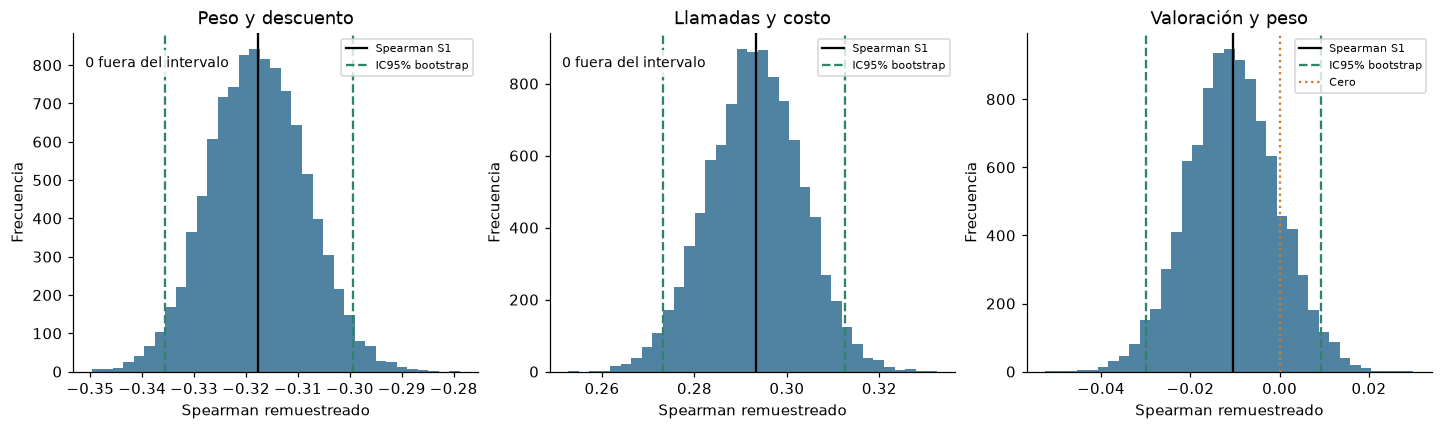

**Peso y descuento:** ρ = **-0.318**, IC95% **[-0.336; -0.299]**, anchura 0.036. El intervalo excluye cero: **negativo estable**.

**Llamadas y costo:** ρ = **0.293**, IC95% **[0.273; 0.313]**, anchura 0.039. El intervalo excluye cero: **positivo estable**.

**Valoración y peso:** ρ = **-0.010**, IC95% **[-0.030; 0.009]**, anchura 0.039. El intervalo incluye cero: **signo no resuelto**.

In [7]:
def spearman_por_lote(x, y, axis=-1):
    """Spearman = Pearson de rangos recalculados; admite lotes y empates."""
    rx = stats.rankdata(x, axis=axis, method="average")
    ry = stats.rankdata(y, axis=axis, method="average")
    rx = rx - rx.mean(axis=axis, keepdims=True)
    ry = ry - ry.mean(axis=axis, keepdims=True)
    return np.sum(rx * ry, axis=axis) / np.sqrt(
        np.sum(rx**2, axis=axis) * np.sum(ry**2, axis=axis))

def bootstrap_correlacion(datos_pares, semilla):
    """Remuestrea filas completas del par; preserva su asociación."""
    x, y = datos_pares.to_numpy(dtype=float).T
    np.testing.assert_allclose(spearman_por_lote(x, y), stats.spearmanr(x, y).statistic)
    resultado = stats.bootstrap((x, y), spearman_por_lote, paired=True,
        vectorized=True, n_resamples=B, batch=LOTE, method="percentile",
        confidence_level=0.95, rng=np.random.default_rng(semilla))
    valores = resultado.bootstrap_distribution
    assert len(valores) == B and np.isfinite(valores).all()
    return valores, np.array(resultado.confidence_interval)

distribuciones_rho, filas = {}, []
for (a, b, nombre), semilla in zip(PARES, SEMILLAS["correlaciones"]):
    pares = df[[a, b]].dropna()
    valores, intervalo = bootstrap_correlacion(pares, semilla)
    distribuciones_rho[nombre] = valores
    contiene_cero = bool(intervalo[0] <= 0 <= intervalo[1])
    signo = "Signo no resuelto" if contiene_cero else ("Negativo estable" if intervalo[1] < 0 else "Positivo estable")
    filas.append({"relacion": nombre, "n": len(pares),
        "rho_s1": stats.spearmanr(pares[a], pares[b]).statistic,
        "ic_inf": intervalo[0], "ic_sup": intervalo[1],
        "ancho_ic": intervalo[1] - intervalo[0], "ee_bootstrap": valores.std(ddof=1),
        "incluye_cero": contiene_cero, "signo": signo})
correlaciones = pd.DataFrame(filas).set_index("relacion")
# Tabla de presentación de resultados
tabla_correlaciones = correlaciones.copy()
tabla_correlaciones["IC bootstrap 95 %"] = tabla_correlaciones.apply(lambda r: f"[{r['ic_inf']:.4f}; {r['ic_sup']:.4f}]", axis=1)
tabla_correlaciones = tabla_correlaciones[[
    "n",
    "rho_s1",
    "IC bootstrap 95 %",
    "ee_bootstrap",
    "ancho_ic",
    "incluye_cero",
    "signo"
]]

display(tabla_correlaciones.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, (nombre, r) in zip(axes, correlaciones.iterrows()):
    ax.hist(distribuciones_rho[nombre], bins=35, color=AZUL, alpha=0.8)
    ax.axvline(r.rho_s1, color="black", label="Spearman S1")
    ax.axvline(r.ic_inf, color=VERDE, ls="--", label="IC95% bootstrap")
    ax.axvline(r.ic_sup, color=VERDE, ls="--")
    # Si el cero queda muy lejos, se indica en texto para no comprimir el histograma.
    if r.ic_inf - r.ancho_ic <= 0 <= r.ic_sup + r.ancho_ic:
        ax.axvline(0, color=NARANJA, ls=":", label="Cero")
    else:
        ax.text(0.03, 0.9, "0 fuera del intervalo", transform=ax.transAxes, fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
    ax.set(title=nombre, xlabel="Spearman remuestreado", ylabel="Frecuencia")
    ax.legend(fontsize=7, loc="upper right")
plt.show()
plt.close(fig)

for nombre, r in correlaciones.iterrows():
    display(Markdown(f"**{nombre}:** ρ = **{r.rho_s1:.3f}**, IC95% "
        f"**[{r.ic_inf:.3f}; {r.ic_sup:.3f}]**, anchura {r.ancho_ic:.3f}. "
        f"El intervalo {'incluye' if r.incluye_cero else 'excluye'} cero: **{r.signo.lower()}**."))

**Conclusión sencilla.** Peso–descuento mantiene un signo negativo y llamadas–costo, uno positivo. Son asociaciones de magnitud limitada, no relaciones deterministas. Valoración–peso permanece cerca de cero: su signo no queda resuelto, pero el intervalo estrecho descarta asociaciones monotónicas grandes bajo estos supuestos.

No se identifica alta variabilidad en estas tres estimaciones. No corresponde inventar una correlación inestable para completar la clasificación. La estabilidad frente al remuestreo tampoco garantiza estabilidad frente a cambios en la composición del conjunto; peso–descuento se revisa nuevamente en la sección 7.

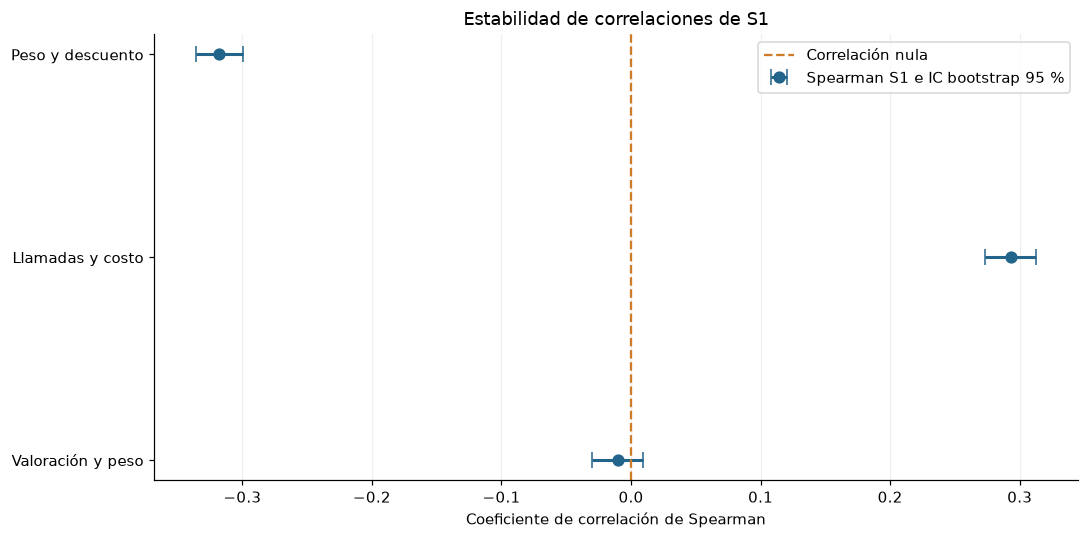

In [8]:
# Comparación de correlaciones e IC bootstrap al 95 %
# Se reutilizan los resultados de 10.000 remuestras.

tabla_corr = correlaciones.reset_index().copy()

fig, ax = plt.subplots(figsize=(10, 5))

y = np.arange(len(tabla_corr))

rho = tabla_corr["rho_s1"].to_numpy()
ic_inf = tabla_corr["ic_inf"].to_numpy()
ic_sup = tabla_corr["ic_sup"].to_numpy()

errores = np.vstack([
    rho - ic_inf,
    ic_sup - rho
])

ax.errorbar(
    rho, y,
    xerr=errores,
    fmt="o",
    color=AZUL,
    ecolor=AZUL,
    capsize=5,
    markersize=7,
    linewidth=2,
    label="Spearman S1 e IC bootstrap 95 %"
)

ax.axvline(
    0,
    color=NARANJA,
    linestyle="--",
    linewidth=1.5,
    label="Correlación nula"
)

ax.set_yticks(y)
ax.set_yticklabels(tabla_corr["relacion"])
ax.invert_yaxis()

ax.set_xlabel("Coeficiente de correlación de Spearman")
ax.set_title("Estabilidad de correlaciones de S1")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

**Comparación de estabilidad de las correlaciones**

El gráfico comparativo de los intervalos de confianza bootstrap al 95 % permite evaluar conjuntamente la estabilidad de las tres correlaciones de Spearman seleccionadas de la Sumativa 1, utilizando 10.000 remuestras por relación.

Los resultados muestran que las asociaciones entre peso y descuento, y entre llamadas de atención y costo del producto, mantienen sus signos negativo y positivo, respectivamente, dado que sus intervalos de confianza no incluyen el valor cero. Esto respalda la consistencia de la dirección de ambas asociaciones frente al remuestreo, aunque sus magnitudes son limitadas y no permiten establecer relaciones causales.

Por su parte, la correlación entre valoración del cliente y peso del producto presenta un intervalo que incluye cero. Este resultado indica que no existe evidencia suficiente para confirmar la dirección de una asociación monotónica entre ambas variables. Sin embargo, la reducida amplitud del intervalo sugiere que esta incertidumbre no se debe necesariamente a una elevada variabilidad del estimador, sino a la pequeña magnitud de la asociación observada.

En conjunto, los resultados respaldan la estabilidad del signo de dos de las tres correlaciones analizadas. No obstante, esta estabilidad debe interpretarse exclusivamente en el contexto del remuestreo bootstrap, sin asumir que las asociaciones permanecerán invariantes frente a cambios en la composición de los datos, presencia de valores extremos u otros supuestos metodológicos. Estas consideraciones se profundizan en el análisis de robustez de la sección 7.

## 6. Monte Carlo: repetir un estudio con los parámetros de S1

**Pregunta.** Si se repitiera un estudio del mismo tamaño, bajo un modelo basado en S1, ¿cuánto variaría la diferencia de peso medio entre entregas fuera de plazo y puntuales?

Se define $\Delta=\bar X_{fuera}-\bar X_{tiempo}$. Un resultado negativo significa que los envíos fuera de plazo pesan menos **en promedio**.

**Diseño.** Se generan pesos positivos con una distribución lognormal por grupo. En cada una de 10.000 iteraciones se simulan 3.992 pesos de entregas puntuales y 5.907 de entregas fuera de plazo, y se calcula la diferencia de medias. Las únicas entradas estimadas son **n, media y desviación estándar recuperadas de S1**. La distribución elegida es un supuesto de S2, no un resultado de S1.

Para una media $m$ y desviación $s$ de S1, los parámetros en escala logarítmica se obtienen por momentos:

$$\sigma_{\log}^2=\log(1+s^2/m^2),\qquad \mu_{\log}=\log(m)-\sigma_{\log}^2/2.$$

La lognormal evita pesos negativos y permite asimetría. No se afirma que describa perfectamente los pesos observados: puede generar valores fuera del rango de S1. En la sección 7 se compara con Gamma y con bootstrap. El foco es la **diferencia de medias**, no la predicción de pesos extremos.

**Convergencia.** Se revisan 1.000, 2.500, 5.000 y 10.000 iteraciones. Se distingue la DE de las diferencias (variación entre estudios) del error Monte Carlo de su media, $DE/\sqrt{M}$ (precisión numérica). Como controles operativos, se exige error numérico menor al 2 % del error estándar de S1, discrepancia con la media teórica menor a tres errores Monte Carlo y cambio de percentiles entre 5.000 y 10.000 menor al 10 % del error estándar de S1. Son tolerancias numéricas declaradas, no pruebas de validez del modelo.

,iteraciones,media,de,p2_5,p97_5,error_mc_media
Monte Carlo lognormal,10000,-892.8373,31.8897,-954.9105,-830.6137,0.3189


Referencia teórica del modelo: media = -892.316 g; DE = 32.289 g.
IC95% Welch de S1: [-955.611; -829.021] g.


,iteraciones,media,de,p2_5,p97_5,error_mc_media,desvio_media_teorica,cambio_max_percentiles
0,1000,-890.3758,32.4428,-953.1792,-826.6806,1.0259,1.9401,NaN
1,2500,-892.1167,31.9180,-954.4745,-829.8065,0.6384,0.1991,3.1259
2,5000,-892.4401,31.7710,-955.0020,-829.8362,0.4493,-0.1242,0.5276
3,10000,-892.8373,31.8897,-954.9105,-830.6137,0.3189,-0.5214,0.7775


,Control cumplido
Error MC < 2% del error estándar S1,True
Media simulada a menos de 3 errores MC de la teórica,True
Cambio de percentiles < 10% del error estándar S1,True


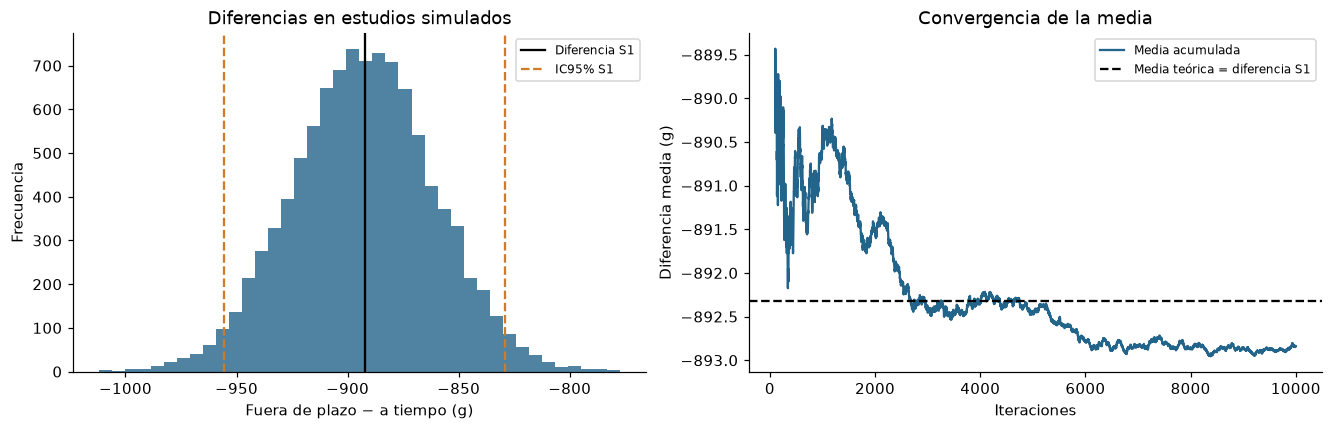

**Lectura del resultado.** La diferencia simulada promedio es **-892.84 g**; el 95 % central de las diferencias va de **-954.91 a -830.61 g**. La variación entre estudios (DE) es **31.89 g**, y el error numérico de su media es **0.319 g**. Los percentiles cambian como máximo **0.778 g** entre 5.000 y 10.000 iteraciones. Los tres controles numéricos se cumplen.

In [9]:
def simular_diferencias(familia, semilla, media_fuera=None):
    """Genera dos muestras completas por iteración y devuelve fuera - a tiempo."""
    rng = np.random.default_rng(semilla)
    salida = np.empty(M)
    parametros = grupos_s1[["n", "media", "de"]].copy()
    if media_fuera is not None:
        parametros.loc["Fuera de plazo", "media"] = media_fuera
    for inicio in range(0, M, LOTE):
        cantidad = min(LOTE, M - inicio)
        medias = []
        for _, r in parametros.iterrows():
            forma = (cantidad, int(r.n))
            if familia == "lognormal":
                sigma2 = np.log1p((r.de / r.media)**2)
                muestra = rng.lognormal(np.log(r.media) - sigma2 / 2, np.sqrt(sigma2), size=forma)
            elif familia == "gamma":
                muestra = rng.gamma(shape=(r.media/r.de)**2, scale=r.de**2/r.media, size=forma)
            else:
                raise ValueError("Familia no reconocida.")
            medias.append(muestra.mean(axis=1))
        salida[inicio:inicio+cantidad] = medias[1] - medias[0]
    return salida

def resumir_distribucion(valores):
    """Resumen numérico sin confundir DE y error Monte Carlo de la media."""
    q = np.quantile(valores, [0.025, 0.975])
    return {"iteraciones": len(valores), "media": valores.mean(),
            "de": valores.std(ddof=1), "p2_5": q[0], "p97_5": q[1],
            "error_mc_media": valores.std(ddof=1) / np.sqrt(len(valores))}

mc_lognormal = simular_diferencias("lognormal", SEMILLAS["lognormal"])
resumen_mc = resumir_distribucion(mc_lognormal)
display(pd.DataFrame([resumen_mc], index=["Monte Carlo lognormal"]).round(4))
print(f"Referencia teórica del modelo: media = {delta_s1:.3f} g; DE = {ee_delta:.3f} g.")
print(f"IC95% Welch de S1: [{ic_delta_s1[0]:.3f}; {ic_delta_s1[1]:.3f}] g.")

cortes = [1_000, 2_500, 5_000, M]
convergencia = pd.DataFrame([resumir_distribucion(mc_lognormal[:k]) for k in cortes])
convergencia["desvio_media_teorica"] = convergencia.media - delta_s1
convergencia["cambio_max_percentiles"] = convergencia[["p2_5", "p97_5"]].diff().abs().max(axis=1)
display(convergencia.round(4))
cambio_percentiles = float(convergencia.iloc[-1].cambio_max_percentiles)
controles_convergencia = {
    "Error MC < 2% del error estándar S1": resumen_mc["error_mc_media"] < 0.02 * ee_delta,
    "Media simulada a menos de 3 errores MC de la teórica": abs(resumen_mc["media"]-delta_s1) < 3*resumen_mc["error_mc_media"],
    "Cambio de percentiles < 10% del error estándar S1": cambio_percentiles < 0.10 * ee_delta,
}
display(pd.Series(controles_convergencia, name="Control cumplido").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axes[0].hist(mc_lognormal, bins=40, color=AZUL, alpha=0.8)
axes[0].axvline(delta_s1, color="black", label="Diferencia S1")
for i, limite in enumerate(ic_delta_s1):
    axes[0].axvline(limite, color=NARANJA, ls="--", label="IC95% S1" if i == 0 else None)
axes[0].set(title="Diferencias en estudios simulados", xlabel="Fuera de plazo − a tiempo (g)", ylabel="Frecuencia")
axes[0].legend(fontsize=8)
eje = np.arange(1, M+1)
acumulada = np.cumsum(mc_lognormal) / eje
axes[1].plot(eje[99:], acumulada[99:], color=AZUL, label="Media acumulada")
axes[1].axhline(delta_s1, color="black", ls="--", label="Media teórica = diferencia S1")
axes[1].set(title="Convergencia de la media", xlabel="Iteraciones", ylabel="Diferencia media (g)")
axes[1].legend(fontsize=8)
plt.show()
plt.close(fig)

display(Markdown(f"**Lectura del resultado.** La diferencia simulada promedio es **{resumen_mc['media']:.2f} g**; "
    f"el 95 % central de las diferencias va de **{resumen_mc['p2_5']:.2f} a {resumen_mc['p97_5']:.2f} g**. "
    f"La variación entre estudios (DE) es **{resumen_mc['de']:.2f} g**, y el error numérico de su media es "
    f"**{resumen_mc['error_mc_media']:.3f} g**. Los percentiles cambian como máximo **{cambio_percentiles:.3f} g** "
    f"entre 5.000 y 10.000 iteraciones. "
    f"{'Los tres controles numéricos se cumplen.' if all(controles_convergencia.values()) else 'Revisar convergencia y aumentar M antes de entregar.'}"))

**Conclusión sencilla.** Bajo el modelo calibrado, la diferencia de peso conserva la dirección observada en S1 y su variación es pequeña frente a una brecha cercana a 892 g. Esto ayuda a dimensionar cuánto cambiaría el resultado al repetir un estudio comparable.

El acuerdo con S1 es parcialmente esperado: la simulación se calibra con sus propias medias y desviaciones. Los percentiles simulados son un **intervalo de variación bajo el modelo**; no son una nueva prueba de que el modelo sea verdadero, ni una evaluación de cobertura del IC de S1. Tampoco estiman el efecto de cambiar el peso sobre la puntualidad: los grupos están definidos por un estado de entrega observado.

## 7. Robustez: ¿qué cambia al retirar observaciones o variar supuestos?

### 7.1. Influencia de un envío: jackknife de las tres medias

Se calcula cuánto cambia cada media al omitir **una observación a la vez**. Para la media no es necesario reconstruir miles de tablas:

$$\bar x_{(-i)}=\frac{n\bar x-x_i}{n-1},\qquad cambio_i=\bar x_{(-i)}-\bar x.$$

Se muestran los tres ID de mayor cambio absoluto por variable. Se informa el cambio en sus unidades y como fracción del error estándar de S1; no existe aquí un umbral estadístico universal para declarar una observación problemática. En caso de empate se ordena por ID. Ser el caso más influyente de esta lista no significa ser un error.

In [10]:
filas_influencia, resumen_influencia = [], []
for variable in VARIABLES:
    datos = df[["ID", variable]].dropna()
    x = datos[variable].to_numpy()
    base = base_medias.loc[variable]
    medias_sin_uno = (x.sum() - x) / (len(x) - 1)
    cambios = medias_sin_uno - x.mean()
    ee_jackknife = np.sqrt((len(x)-1)/len(x) * np.sum((medias_sin_uno-medias_sin_uno.mean())**2))
    casos = pd.DataFrame({"variable": variable, "ID": datos.ID.to_numpy(),
        "valor": x, "media_sin_caso": medias_sin_uno, "cambio_media": cambios,
        "cambio_abs_en_ee": np.abs(cambios)/base.ee})
    filas_influencia.append(casos.sort_values(["cambio_abs_en_ee", "ID"], ascending=[False, True]).head(3))
    resumen_influencia.append({"variable": variable, "max_cambio_absoluto": np.abs(cambios).max(),
        "max_cambio_en_ee": np.abs(cambios).max()/base.ee,
        "ee_s1": base.ee, "ee_jackknife": ee_jackknife})
influencia = pd.concat(filas_influencia, ignore_index=True)
resumen_influencia = pd.DataFrame(resumen_influencia).set_index("variable")
display(influencia.round(6))
display(resumen_influencia.rename(index=NOMBRES).round(6))
max_influencia_ee = resumen_influencia.max_cambio_en_ee.max()
display(Markdown(f"**Conclusión.** El mayor cambio individual equivale a **{max_influencia_ee:.4f}** "
    "errores estándar de S1. Ninguno de los casos listados domina las medias: el efecto individual es pequeño "
    "frente a la incertidumbre de estimación. Esto no descarta una influencia importante de muchos valores altos juntos."))

,variable,ID,valor,media_sin_caso,cambio_media,cambio_abs_en_ee
0,Weight_in_gms,200,7846.0,3633.4547,-0.4256,0.0259
1,Weight_in_gms,199,7640.0,3633.4756,-0.4047,0.0246
2,Weight_in_gms,206,7588.0,3633.4808,-0.3995,0.0243
3,Cost_of_the_Product,432,96.0,210.2507,0.0115,0.0239
4,Cost_of_the_Product,975,96.0,210.2507,0.0115,0.0239
5,Cost_of_the_Product,2419,96.0,210.2507,0.0115,0.0239
6,Discount_offered,112,65.0,13.3685,-0.0047,0.0304
7,Discount_offered,159,65.0,13.3685,-0.0047,0.0304
8,Discount_offered,241,65.0,13.3685,-0.0047,0.0304


,max_cambio_absoluto,max_cambio_en_ee,ee_s1,ee_jackknife
variable,,,,
Peso (g),0.4256,0.0259,16.4446,16.4446
Costo (USD),0.0115,0.0239,0.4829,0.4829
Descuento (unidad no indicada),0.0047,0.0304,0.1545,0.1545


**Conclusión.** El mayor cambio individual equivale a **0.0304** errores estándar de S1. Ninguno de los casos listados domina las medias: el efecto individual es pequeño frente a la incertidumbre de estimación. Esto no descarta una influencia importante de muchos valores altos juntos.

### 7.2. Sensibilidad colectiva a valores extremos

Se identifican valores fuera de $[Q_1-1,5RIC;\ Q_3+1,5RIC]$, usando la misma regla exploratoria de S1. Se auditan las tres variables. Para descuento se compara el análisis completo con un escenario que excluye esos casos, recalculando su media, IC bootstrap y correlación con peso.

**La exclusión es solo un escenario de sensibilidad.** Al retirar una parte importante de la muestra, cambia la población descrita. No se sobrescribe `df` ni se utiliza este escenario como base principal.

,limite_inf,limite_sup,n_validos,marcados,porcentaje
variable,,,,,
Peso (g),-2976.5,9867.5,9899,0,0.000
Costo (USD),48.5,372.5,9899,0,0.000
Descuento (unidad no indicada),-5.0,19.0,10999,2209,20.084


,estimador,n_base,n_escenario,base,escenario,ic_base_inf,ic_base_sup,ic_escenario_inf,ic_escenario_sup,cambio
0,Media descuento (IC BCa),10999,8790,13.3732,5.9751,13.0721,13.6836,5.9017,6.0481,-7.3981
1,Spearman peso–descuento (IC percentil),9899,7902,-0.3177,-0.0776,-0.3357,-0.2994,-0.0994,-0.0558,0.2400


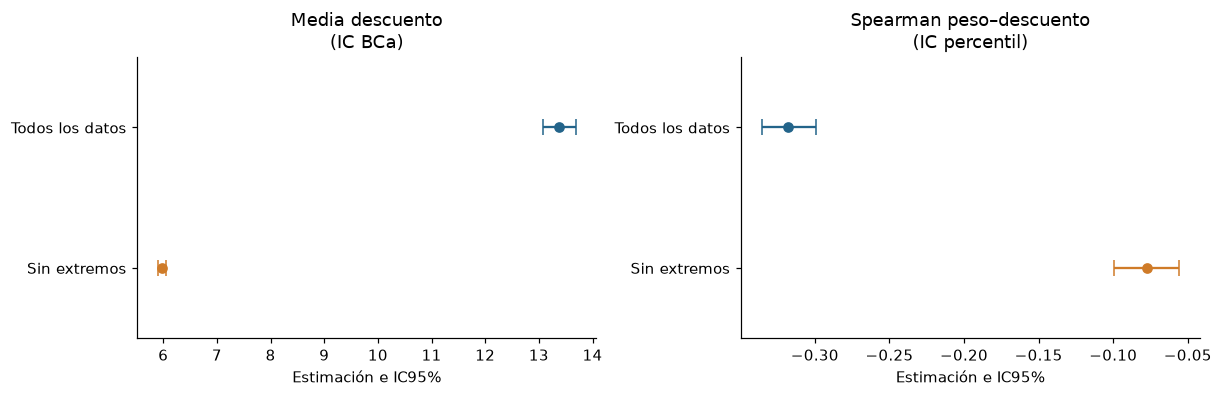

**Conclusión.** La regla marca **2,209 envíos (20.08%)**. Al retirarlos, la media del descuento pasa de **13.373 a 5.975** (-55.32%). Spearman peso–descuento pasa de **-0.318 a -0.078**. La media y la magnitud de esta asociación son sensibles a la composición de los descuentos. El cambio colectivo es mucho mayor que el de retirar un solo envío.

In [11]:
filas = []
for variable in VARIABLES:
    x = df[variable].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    inferior, superior = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    fuera = (x < inferior) | (x > superior)
    filas.append({"variable": variable, "limite_inf": inferior, "limite_sup": superior,
        "n_validos": len(x), "marcados": int(fuera.sum()), "porcentaje": 100*fuera.mean()})
auditoria_extremos = pd.DataFrame(filas).set_index("variable")
display(auditoria_extremos.rename(index=NOMBRES).round(3))

limites = auditoria_extremos.loc["Discount_offered"]
conservar = df.Discount_offered.between(limites.limite_inf, limites.limite_sup)
df_sensible = df.loc[conservar].copy()
n_excluidos = int((~conservar).sum())
dist_desc_filtrado, pct_desc_filtrado, bca_desc_filtrado = bootstrap_media(
    df_sensible.Discount_offered, SEMILLAS["descuento_filtrado"])
pares_filtrados = df_sensible[["Weight_in_gms", "Discount_offered"]].dropna()
dist_rho_filtrado, ic_rho_filtrado = bootstrap_correlacion(pares_filtrados, SEMILLAS["correlacion_filtrada"])
media_desc_filtrado = df_sensible.Discount_offered.mean()
rho_filtrado = stats.spearmanr(pares_filtrados.iloc[:, 0], pares_filtrados.iloc[:, 1]).statistic
desc_base = bootstrap_medias.loc["Discount_offered"]
rho_base = correlaciones.loc["Peso y descuento"]
sensibilidad_extremos = pd.DataFrame([
    {"estimador": "Media descuento (IC BCa)", "n_base": len(df), "n_escenario": len(df_sensible),
     "base": desc_base.media, "escenario": media_desc_filtrado,
     "ic_base_inf": desc_base.bca_inf, "ic_base_sup": desc_base.bca_sup,
     "ic_escenario_inf": bca_desc_filtrado[0], "ic_escenario_sup": bca_desc_filtrado[1]},
    {"estimador": "Spearman peso–descuento (IC percentil)", "n_base": int(rho_base.n), "n_escenario": len(pares_filtrados),
     "base": rho_base.rho_s1, "escenario": rho_filtrado,
     "ic_base_inf": rho_base.ic_inf, "ic_base_sup": rho_base.ic_sup,
     "ic_escenario_inf": ic_rho_filtrado[0], "ic_escenario_sup": ic_rho_filtrado[1]},
])
sensibilidad_extremos["cambio"] = sensibilidad_extremos.escenario - sensibilidad_extremos.base
display(sensibilidad_extremos.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, (_, r) in zip(axes, sensibilidad_extremos.iterrows()):
    for y, valor, inf, sup, color in [
        (1, r.base, r.ic_base_inf, r.ic_base_sup, AZUL),
        (0, r.escenario, r.ic_escenario_inf, r.ic_escenario_sup, NARANJA)]:
        ax.errorbar(valor, y, xerr=[[valor-inf], [sup-valor]], fmt="o", color=color, capsize=5)
    ax.set(yticks=[0, 1], yticklabels=["Sin extremos", "Todos los datos"],
           title=r.estimador.replace(" (", "\n("), xlabel="Estimación e IC95%", ylim=(-0.5, 1.5))
plt.show()
plt.close(fig)

cambio_desc_pct = 100*(media_desc_filtrado/desc_base.media-1)
display(Markdown(f"**Conclusión.** La regla marca **{n_excluidos:,} envíos ({100*n_excluidos/len(df):.2f}%)**. "
    f"Al retirarlos, la media del descuento pasa de **{desc_base.media:.3f} a {media_desc_filtrado:.3f}** "
    f"({cambio_desc_pct:+.2f}%). Spearman peso–descuento pasa de **{rho_base.rho_s1:.3f} a {rho_filtrado:.3f}**. "
    "La media y la magnitud de esta asociación son sensibles a la composición de los descuentos. "
    "El cambio colectivo es mucho mayor que el de retirar un solo envío."))

Peso y costo no presentan casos fuera de sus cercas de 1,5 RIC: con esta regla no habría una exclusión adicional que comparar en esas variables. Esto no demuestra ausencia de valores problemáticos bajo otros criterios.

Los descuentos altos pueden ser parte legítima del negocio. Para S3 se recomienda conservarlos, revisar su significado y complementar la media con mediana, cuantiles y análisis por grupos de descuento. La asociación peso–descuento mantiene un signo negativo en el escenario, pero pierde buena parte de su magnitud. Por tanto, **signo estable no equivale a magnitud robusta**.

### 7.3. Sensibilidad a la distribución supuesta

Se compara el escenario lognormal con una **Gamma** que conserva exactamente las mismas medias y desviaciones de S1: forma $k=(m/s)^2$ y escala $\theta=s^2/m$. Cada escenario utiliza 10.000 estudios simulados completos.

Como contraste adicional, se hace bootstrap de la diferencia de medias, remuestreando **por separado dentro de cada estado de entrega** y manteniendo los tamaños. Así no se impone una familia de distribución para los pesos.

Los percentiles de Monte Carlo describen variación bajo cada modelo; el IC percentil bootstrap estima incertidumbre por remuestreo de los datos. Su comparación es una comprobación de sensibilidad, no los convierte en intervalos conceptualmente idénticos.

,iteraciones,media,de,p2_5,p97_5,error_mc_media,ancho_95,cambio_media_vs_s1,cambio_de_vs_s1_pct
metodo,,,,,,,,,
Monte Carlo lognormal,10000,-892.8373,31.8897,-954.9105,-830.6137,0.3189,124.2967,-0.5214,-1.2376
Monte Carlo Gamma,10000,-892.7281,32.2256,-956.8475,-829.8741,0.3223,126.9734,-0.4122,-0.1974
Bootstrap por estado,10000,-892.8424,32.3075,-955.8424,-830.7665,0.3231,125.0759,-0.5265,0.0565


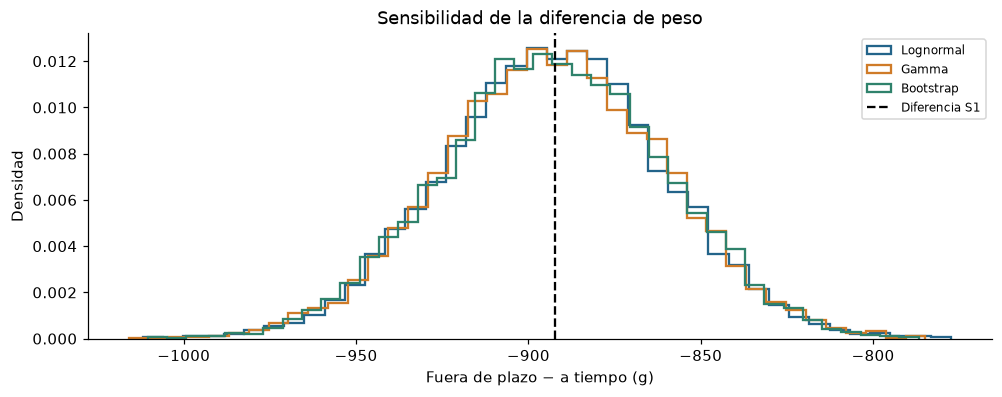

**Resultado.** La mayor diferencia relativa entre la DE calculada y el error estándar de S1 es **1.24%**. Los tres intervalos centrales permanecen por debajo de cero. La dirección y la escala de incertidumbre de la diferencia son similares con los métodos examinados.

In [12]:
mc_gamma = simular_diferencias("gamma", SEMILLAS["gamma"])

def diferencia_medias(fuera, tiempo, axis=-1):
    return fuera.mean(axis=axis) - tiempo.mean(axis=axis)

boot_delta = stats.bootstrap((peso_fuera, peso_tiempo), diferencia_medias,
    paired=False, vectorized=True, n_resamples=B, batch=LOTE,
    method="percentile", confidence_level=0.95,
    rng=np.random.default_rng(SEMILLAS["diferencia_bootstrap"]))
dist_delta_boot = boot_delta.bootstrap_distribution
comparacion_modelos = pd.DataFrame([
    {"metodo": "Monte Carlo lognormal", **resumir_distribucion(mc_lognormal)},
    {"metodo": "Monte Carlo Gamma", **resumir_distribucion(mc_gamma)},
    {"metodo": "Bootstrap por estado", **resumir_distribucion(dist_delta_boot)},
]).set_index("metodo")
comparacion_modelos["ancho_95"] = comparacion_modelos.p97_5 - comparacion_modelos.p2_5
comparacion_modelos["cambio_media_vs_s1"] = comparacion_modelos.media - delta_s1
comparacion_modelos["cambio_de_vs_s1_pct"] = 100*(comparacion_modelos.de/ee_delta-1)
display(comparacion_modelos.round(4))

fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
for valores, nombre, color in [(mc_lognormal, "Lognormal", AZUL),
        (mc_gamma, "Gamma", NARANJA), (dist_delta_boot, "Bootstrap", VERDE)]:
    ax.hist(valores, bins=40, density=True, histtype="step", lw=1.5, label=nombre, color=color)
ax.axvline(delta_s1, color="black", ls="--", label="Diferencia S1")
ax.set(title="Sensibilidad de la diferencia de peso", xlabel="Fuera de plazo − a tiempo (g)", ylabel="Densidad")
ax.legend(fontsize=8)
plt.show()
plt.close(fig)

desvio_de_max = comparacion_modelos.cambio_de_vs_s1_pct.abs().max()
display(Markdown(f"**Resultado.** La mayor diferencia relativa entre la DE calculada y el error estándar "
    f"de S1 es **{desvio_de_max:.2f}%**. Los tres intervalos centrales "
    f"{'permanecen por debajo' if (comparacion_modelos.p97_5 < 0).all() else 'no permanecen todos por debajo'} "
    "de cero. La dirección y la escala de incertidumbre de la diferencia son similares con los métodos examinados."))

**Interpretación.** La comparación respalda la diferencia de medias frente a estos cambios concretos de distribución. El acuerdo entre Lognormal y Gamma es esperable porque comparten media y varianza y los grupos son grandes. No valida la forma completa de los pesos ni su comportamiento en las colas. El bootstrap añade evidencia sin imponer esas familias, pero sigue dependiendo de la muestra observada y de la independencia de los envíos.

### 7.4. Sensibilidad a las entradas de la simulación

Para evaluar también el impacto de los parámetros, se usan como escenarios la diferencia central de S1 y los dos extremos de su IC de Welch. Se mantiene fija la media del grupo a tiempo y se define:

$$m_{fuera,escenario}=m_{tiempo,S1}+\Delta_{escenario}.$$

Los tamaños y desviaciones permanecen en los valores de S1. Se simulan 10.000 estudios lognormales por escenario. Estos extremos son **valores alternativos plausibles de la diferencia según S1**, no cambios causados por una intervención. Se analizan por separado; no se mezclan para construir un nuevo IC ni representan toda la incertidumbre conjunta de los parámetros.

,delta_entrada,media_fuera_entrada,iteraciones,media,de,p2_5,p97_5,error_mc_media
escenario,,,,,,,,
Extremo inferior IC S1,-955.611,3210.739,10000,-955.422,32.593,-1019.374,-891.394,0.326
Central S1,-892.316,3274.033,10000,-892.837,31.890,-954.910,-830.614,0.319
Extremo superior IC S1,-829.021,3337.328,10000,-829.415,32.394,-892.981,-765.628,0.324


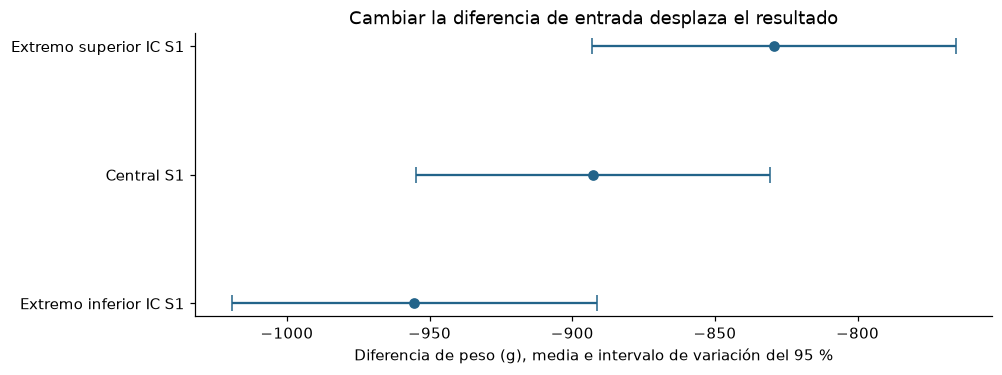

**Conclusión.** Al usar diferencias de entrada entre **-955.61 y -829.02 g**, las medias simuladas van de **-955.42 a -829.41 g**. Todos los intervalos de variación quedan por debajo de cero. La magnitud se mueve con la entrada, como corresponde; la dirección se mantiene dentro del rango estudiado. No es una garantía frente a otros escenarios o sesgos de muestreo.

In [13]:
escenarios = []
distribuciones_escenarios = {}
for nombre, objetivo_delta, semilla in [
    ("Extremo inferior IC S1", ic_delta_s1[0], SEMILLAS["escenario_inferior"]),
    ("Central S1", delta_s1, SEMILLAS["lognormal"]),
    ("Extremo superior IC S1", ic_delta_s1[1], SEMILLAS["escenario_superior"])]:
    nueva_media = grupos_s1.loc["A tiempo", "media"] + objetivo_delta
    valores = mc_lognormal if nombre == "Central S1" else simular_diferencias("lognormal", semilla, nueva_media)
    distribuciones_escenarios[nombre] = valores
    escenarios.append({"escenario": nombre, "delta_entrada": objetivo_delta,
        "media_fuera_entrada": nueva_media, **resumir_distribucion(valores)})
sensibilidad_entradas = pd.DataFrame(escenarios).set_index("escenario")
display(sensibilidad_entradas.round(3))

fig, ax = plt.subplots(figsize=(9, 3.3), constrained_layout=True)
for i, (nombre, r) in enumerate(sensibilidad_entradas.iterrows()):
    ax.errorbar(r.media, i, xerr=[[r.media-r.p2_5], [r.p97_5-r.media]], fmt="o", capsize=5, color=AZUL)
ax.set(yticks=range(len(sensibilidad_entradas)), yticklabels=sensibilidad_entradas.index,
       xlabel="Diferencia de peso (g), media e intervalo de variación del 95 %",
       title="Cambiar la diferencia de entrada desplaza el resultado")
plt.show()
plt.close(fig)

display(Markdown(f"**Conclusión.** Al usar diferencias de entrada entre **{ic_delta_s1[0]:.2f} y "
    f"{ic_delta_s1[1]:.2f} g**, las medias simuladas van de **{sensibilidad_entradas.media.min():.2f} "
    f"a {sensibilidad_entradas.media.max():.2f} g**. "
    f"{'Todos' if (sensibilidad_entradas.p97_5 < 0).all() else 'No todos'} los intervalos de variación quedan "
    "por debajo de cero. La magnitud se mueve con la entrada, como corresponde; la dirección se mantiene "
    "dentro del rango estudiado. No es una garantía frente a otros escenarios o sesgos de muestreo."))

## 8. Conclusiones y preparación para S3

La síntesis distingue tres conceptos: **precisión** (incertidumbre de la estimación), **estabilidad** (consistencia al remuestrear) y **robustez** (sensibilidad a los cambios concretos que se examinaron). Un resultado puede ser preciso y sensible a la vez.

In [14]:
sintesis = pd.DataFrame([
    {"resultado": "Media de peso", "evaluacion": "Consistente entre IC; baja influencia individual",
     "alcance": "Sin extremos según 1,5 RIC; independencia y representatividad pendientes",
     "recomendacion_s3": "Conservar media e IC BCa como referencia; revisar sesgos y variables operativas"},
    {"resultado": "Media de costo", "evaluacion": "Consistente entre IC; baja influencia individual",
     "alcance": "Sin extremos según 1,5 RIC; análisis sobre casos disponibles",
     "recomendacion_s3": "Conservar media e IC; evaluar imputación sin acceder a verdad reservada durante el ajuste"},
    {"resultado": "Media de descuento", "evaluacion": "Precisa con la muestra completa; sensible a descuentos altos",
     "alcance": "Excluir 20,08% cambia la población descrita; unidad sin confirmar",
     "recomendacion_s3": "Conservar casos; verificar unidad y complementar con mediana, cuantiles y segmentos"},
    {"resultado": "Transporte y puntualidad", "evaluacion": "Pruebas coinciden: no se rechaza independencia",
     "alcance": "No prueba equivalencia ni ausencia de asociación en otra población",
     "recomendacion_s3": "No priorizar cambios de transporte por este resultado aislado"},
    {"resultado": "Peso y descuento", "evaluacion": "Signo negativo estable; magnitud sensible al filtro",
     "alcance": "La asociación se debilita al retirar descuentos altos",
     "recomendacion_s3": "Analizar composición y posibles variables de confusión; evitar interpretación causal"},
    {"resultado": "Llamadas y costo", "evaluacion": "Signo positivo estable frente al remuestreo",
     "alcance": "Asociación limitada; no indica causalidad ni utilidad predictiva asegurada",
     "recomendacion_s3": "Mantener como relación exploratoria; comprobar con validación fuera de muestra"},
    {"resultado": "Valoración y peso", "evaluacion": "Asociación pequeña; IC incluye cero",
     "alcance": "No se confirma el signo; no se observa alta variabilidad",
     "recomendacion_s3": "No priorizar como asociación monotónica fuerte; no descartar otras relaciones"},
    {"resultado": "Diferencia de peso por puntualidad", "evaluacion": "Dirección consistente en los métodos y escenarios evaluados",
     "alcance": "Modelos calibrados con S1; no identifican causas del retraso",
     "recomendacion_s3": "Investigar perfiles, destinos y distancia antes de recomendar intervenciones"},
])
display(sintesis)

display(Markdown(f"""
**Conclusión general.** Los métodos computacionales respaldan varios resultados de S1, pero muestran que el descuento exige cautela. La concordancia entre métodos ayuda a evaluar las estimaciones; no elimina las limitaciones del conjunto de datos.

**Conclusión técnica y estadística.** Las tres medias presentan IC clásicos, percentiles y BCa próximos. La prueba de transporte conserva su decisión (p de permutación = **{p_perm:.4f}**). Dos correlaciones mantienen su signo y valoración–peso permanece cerca de cero. La diferencia de peso, **{delta_s1:.2f} g**, conserva su dirección bajo las distribuciones y entradas examinadas. En cambio, excluir descuentos altos reduce su media **{abs(cambio_desc_pct):.2f}%** y debilita su correlación con peso.

**Conclusión para decisiones.** Estos resultados orientan a investigar perfiles de productos y la composición de los descuentos. No justifican afirmar que cambiar el transporte o el peso reducirá los atrasos. Antes de intervenir conviene incorporar destino, distancia, fecha y duración del retraso, además de verificar la unidad del descuento.

**Continuidad hacia S3.** Se exportan estimaciones e intervalos, correlaciones, ID con mayor influencia individual, escenarios y recomendaciones. Deben conservarse los casos altos salvo evidencia de error. Si se evalúa imputación o predicción, separar entrenamiento y evaluación; usar los valores MCAR reservados solo como verdad de evaluación, nunca para ajustar el método. La estabilidad inferencial aquí observada no garantiza desempeño predictivo.
"""))

,resultado,evaluacion,alcance,recomendacion_s3
0,Media de peso,Consistente entre IC; baja influencia individual,"Sin extremos según 1,5 RIC; independencia y representatividad pendientes",Conservar media e IC BCa como referencia; revisar sesgos y variables operativas
1,Media de costo,Consistente entre IC; baja influencia individual,"Sin extremos según 1,5 RIC; análisis sobre casos disponibles",Conservar media e IC; evaluar imputación sin acceder a verdad reservada durante el ajuste
2,Media de descuento,Precisa con la muestra completa; sensible a descuentos altos,"Excluir 20,08% cambia la población descrita; unidad sin confirmar","Conservar casos; verificar unidad y complementar con mediana, cuantiles y segmentos"
3,Transporte y puntualidad,Pruebas coinciden: no se rechaza independencia,No prueba equivalencia ni ausencia de asociación en otra población,No priorizar cambios de transporte por este resultado aislado
4,Peso y descuento,Signo negativo estable; magnitud sensible al filtro,La asociación se debilita al retirar descuentos altos,Analizar composición y posibles variables de confusión; evitar interpretación causal
5,Llamadas y costo,Signo positivo estable frente al remuestreo,Asociación limitada; no indica causalidad ni utilidad predictiva asegurada,Mantener como relación exploratoria; comprobar con validación fuera de muestra
6,Valoración y peso,Asociación pequeña; IC incluye cero,No se confirma el signo; no se observa alta variabilidad,No priorizar como asociación monotónica fuerte; no descartar otras relaciones
7,Diferencia de peso por puntualidad,Dirección consistente en los métodos y escenarios evaluados,Modelos calibrados con S1; no identifican causas del retraso,"Investigar perfiles, destinos y distancia antes de recomendar intervenciones"



**Conclusión general.** Los métodos computacionales respaldan varios resultados de S1, pero muestran que el descuento exige cautela. La concordancia entre métodos ayuda a evaluar las estimaciones; no elimina las limitaciones del conjunto de datos.

**Conclusión técnica y estadística.** Las tres medias presentan IC clásicos, percentiles y BCa próximos. La prueba de transporte conserva su decisión (p de permutación = **0.6892**). Dos correlaciones mantienen su signo y valoración–peso permanece cerca de cero. La diferencia de peso, **-892.32 g**, conserva su dirección bajo las distribuciones y entradas examinadas. En cambio, excluir descuentos altos reduce su media **55.32%** y debilita su correlación con peso.

**Conclusión para decisiones.** Estos resultados orientan a investigar perfiles de productos y la composición de los descuentos. No justifican afirmar que cambiar el transporte o el peso reducirá los atrasos. Antes de intervenir conviene incorporar destino, distancia, fecha y duración del retraso, además de verificar la unidad del descuento.

**Continuidad hacia S3.** Se exportan estimaciones e intervalos, correlaciones, ID con mayor influencia individual, escenarios y recomendaciones. Deben conservarse los casos altos salvo evidencia de error. Si se evalúa imputación o predicción, separar entrenamiento y evaluación; usar los valores MCAR reservados solo como verdad de evaluación, nunca para ajustar el método. La estabilidad inferencial aquí observada no garantiza desempeño predictivo.


**Limitaciones comunes.** El origen de la muestra y la independencia entre envíos no están confirmados; no se dispone de fechas ni identificadores de cliente para evaluar dependencia temporal o repetición. Los faltantes fueron generados artificialmente con MCAR y no reproducen todos los mecanismos de ausencia reales. Bootstrap y permutación actúan sobre esta muestra; no corrigen representatividad, confusión ni causalidad. Los IC y contrastes son exploratorios e individuales. La convergencia reduce el error numérico, pero no corrige un modelo inadecuado.

### 8.1. Archivo de resultados validados

La siguiente celda crea o actualiza **`data/processed/resultados_validos_s2.json`**, dentro de una carpeta que ya existe. Incluye números con precisión numérica, sin el redondeo de presentación, además de procedencia, semillas, repeticiones, influencias y recomendaciones. Este archivo y el notebook constituyen la entrada analítica para S3; el PDF de S2 se redacta a partir de estas mismas salidas.

In [15]:
# Convertir DataFrames a estructuras JSON sin perder las columnas identificadoras.
def registros(tabla, incluir_indice=False):
    tabla = tabla.reset_index() if incluir_indice else tabla
    return json.loads(tabla.to_json(orient="records", double_precision=15))

try:
    commit_ejecucion = subprocess.run(["git", "-C", str(RAIZ), "rev-parse", "HEAD"],
        capture_output=True, text=True, check=True, timeout=5).stdout.strip()
except (OSError, subprocess.SubprocessError):
    commit_ejecucion = "No disponible; referencia S1 identificada por commit y hash de datos"

resultados_s2 = {
    "schema_version": "1.0", "evaluacion": "Sumativa 2", "equipo": "Grupo 7",
    "procedencia": {
        "repositorio": REPO_URL, "commit_referencia_s1": COMMIT_S1,
        "commit_en_ejecucion": commit_ejecucion,
        "notebook_s1": "notebooks/sumativa_1.ipynb",
        "datos": "data/processed/ecommerce_mcar.csv", "sha256_datos_lf": hash_datos,
        "fecha_utc": datetime.now(timezone.utc).isoformat(), "versiones": VERSIONES,
        "bootstrap_por_analisis": B, "permutaciones": B, "monte_carlo_por_escenario": M,
        "lote": LOTE, "semillas": SEMILLAS, "confianza": 0.95,
        "codificacion": {"0": "a tiempo", "1": "fuera de plazo"},
        "tratamiento_faltantes": "Casos disponibles por variable; pares completos en correlaciones; sin imputación",
        "fuentes_s1": {"medias": "notebook sección 6.1; informe VII",
            "pruebas": "notebook 6.2 y 6.3; informe VIII",
            "correlaciones_y_grupos": "notebook 5.3; informe VI"},
    },
    "medias_validadas": registros(bootstrap_medias, True),
    "permutacion": permutacion,
    "correlaciones": registros(correlaciones, True),
    "monte_carlo": {
        "pregunta": "Variación de la diferencia de peso medio fuera de plazo menos a tiempo en estudios repetidos",
        "parametros_s1": registros(grupos_s1[["n", "media", "de"]], True),
        "diferencia_s1": delta_s1, "ic_welch_s1": ic_delta_s1.tolist(),
        "p_welch_s1": float(welch.pvalue), "error_estandar_s1": ee_delta,
        "modelo_principal": "Lognormal por grupo ajustada por momentos de S1",
        "resultado_principal": resumen_mc, "convergencia": registros(convergencia),
        "controles_convergencia": {k: bool(v) for k, v in controles_convergencia.items()},
        "comparacion_modelos": registros(comparacion_modelos, True),
        "sensibilidad_entradas": registros(sensibilidad_entradas, True),
        "regla_escenarios": "Media a tiempo, DE y n fijos en S1; media fuera = media a tiempo + extremo IC Welch S1",
        "interpretacion_intervalos": "Monte Carlo: variación condicional al modelo; bootstrap: IC percentil de la diferencia",
    },
    "robustez": {
        "influencia_jackknife": registros(influencia),
        "resumen_influencia": registros(resumen_influencia, True),
        "auditoria_extremos": registros(auditoria_extremos, True),
        "sensibilidad_extremos": registros(sensibilidad_extremos),
        "n_excluidos_escenario": n_excluidos,
        "porcentaje_excluido_escenario": 100*n_excluidos/len(df),
        "ic_percentil_descuento_filtrado": pct_desc_filtrado.tolist(),
        "politica": "Retener todos los registros en el análisis principal; la exclusión es solo sensibilidad",
    },
    "sintesis_y_recomendaciones_s3": registros(sintesis),
    "limitaciones": ["Muestreo e independencia no documentados", "Asociaciones no causales",
        "Faltantes MCAR artificiales; incertidumbre condicionada a datos disponibles",
        "Unidad del descuento sin confirmar", "IC y pruebas individuales sin ajuste conjunto",
        "Simulación calibrada con S1: convergencia no implica validez del modelo"],
    "entrega_formal_pendiente": ["PDF de máximo siete páginas",
        "Organización S1/S2 solicitada por la rúbrica; se conserva la estructura actual por instrucción del equipo",
        "Publicar los entregables y el JSON en GitHub y presentar el enlace en Canvas"],
}

# allow_nan=False impide exportar números no válidos como si fueran resultados.
contenido_json = json.dumps(resultados_s2, ensure_ascii=False, indent=2, allow_nan=False)
RUTA_SALIDA.write_text(contenido_json, encoding="utf-8")
print(f"Resultados para S3 guardados: {RUTA_SALIDA.relative_to(RAIZ)}")

Resultados para S3 guardados: data\processed\resultados_validos_s2.json


## 9. Verificación final y referencias

Los siguientes controles verifican la evidencia calculada. No asignan una calificación automática: la interpretación y la entrega completa también se evalúan.

In [16]:
controles = {
    "Datos y cifras de S1 verificados": hash_datos == HASH_DATOS_S1,
    "Tres medias; ≥10.000 remuestras por media": len(distribuciones_medias) == 3 and all(len(x) >= 10_000 for x in distribuciones_medias.values()),
    "IC percentil y BCa finitos y ordenados": bool(np.isfinite(bootstrap_medias[["percentil_inf", "percentil_sup", "bca_inf", "bca_sup"]]).all().all()
        and (bootstrap_medias.percentil_inf < bootstrap_medias.percentil_sup).all()
        and (bootstrap_medias.bca_inf < bootstrap_medias.bca_sup).all()),
    "Permutación: ≥10.000 y p válido": len(chi_nulos) >= 10_000 and 0 < p_perm <= 1,
    "Tres correlaciones, pares e IC95% válidos": len(correlaciones) == 3 and bool((correlaciones.ic_inf < correlaciones.ic_sup).all())
        and all(len(x) >= 10_000 and np.isfinite(x).all() for x in distribuciones_rho.values()),
    "Monte Carlo: ≥10.000 por escenario": all(len(x) >= 10_000 and np.isfinite(x).all()
        for x in [mc_lognormal, mc_gamma, *distribuciones_escenarios.values()]),
    "Convergencia numérica principal comprobada": all(controles_convergencia.values()),
    "Robustez: influencia, extremos, familias y entradas": len(influencia) == 9
        and len(sensibilidad_extremos) == 2 and len(comparacion_modelos) == 3 and len(sensibilidad_entradas) == 3,
    "JSON válido con recomendaciones para S3": len(json.loads(RUTA_SALIDA.read_text(encoding="utf-8"))["sintesis_y_recomendaciones_s3"]) == 8,
    "CSV fuente sin cambios": hashlib.sha256(RUTA_DATOS.read_bytes().replace(b"\r\n", b"\n")).hexdigest() == HASH_DATOS_S1,
}
display(pd.DataFrame({"Control": controles.keys(), "Cumple": [bool(x) for x in controles.values()]}))
assert all(controles.values()), "Hay controles pendientes: revisar antes de entregar."
print("Todos los controles computacionales se cumplen. Guardar el notebook con estas salidas.")

,Control,Cumple
0,Datos y cifras de S1 verificados,True
1,Tres medias; ≥10.000 remuestras por media,True
2,IC percentil y BCa finitos y ordenados,True
3,Permutación: ≥10.000 y p válido,True
4,"Tres correlaciones, pares e IC95% válidos",True
5,Monte Carlo: ≥10.000 por escenario,True
6,Convergencia numérica principal comprobada,True
7,"Robustez: influencia, extremos, familias y entradas",True
8,JSON válido con recomendaciones para S3,True
9,CSV fuente sin cambios,True


Todos los controles computacionales se cumplen. Guardar el notebook con estas salidas.


### Referencias y trazabilidad

1. Universidad Andrés Bello (2026). *Sumativa 2. Informe 3: instrucciones y rúbrica, fase 3*. Documento del curso proporcionado al equipo; seis criterios, 87 puntos.
2. Grupo 7 (2026). [Repositorio de Estadística Computacional, versión S1 `0c7ffac`](https://github.com/jorge170102/ESTAD-STICA-COMPUTACIONAL---Grupo-7--MCDI501.202682.1914.EL.ON/tree/0c7ffaca4e45525ab434f6c9305128221e4ef1c4). Notebook `notebooks/sumativa_1.ipynb`, datos preparados y módulos de inferencia y análisis bivariado.
3. Grupo 7 (2026). *Informe Sumativa 1: factores asociados con la puntualidad de envíos en comercio electrónico*. Informe institucional proporcionado, 12 de octubre de 2026.
4. SciPy. [Bootstrap: percentil, BCa y remuestreo por pares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).
5. SciPy. [Pruebas de permutación y corrección del valor p](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).
6. SciPy. [Correlación de Spearman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

**Antes de entregar:** guardar este notebook con todas sus salidas, elaborar el PDF de máximo siete páginas a partir de estos resultados, incluir el JSON exportado y revisar la condición formal de carpetas S1/S2 y el enlace a GitHub. Este notebook conserva deliberadamente la estructura actual; no modifica los archivos de S1 ni publica cambios en el repositorio.